In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load dataset
df = pd.read_excel("../dataset/Online Retail.xlsx")

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 541909
Total Columns: 8


In [10]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [13]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 5268


In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [11]:
df_clean = df.copy()

In [12]:
print("Before removing duplicates:", len(df_clean))

df_clean = df_clean.drop_duplicates()

print("After removing duplicates:", len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

Before removing duplicates: 541909
After removing duplicates: 536641
Remaining duplicates: 0


In [15]:
df_clean.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [16]:
print("Negative Quantity:", (df_clean["Quantity"] < 0).sum())

print("Zero Quantity:", (df_clean["Quantity"] == 0).sum())

print("Negative UnitPrice:", (df_clean["UnitPrice"] < 0).sum())

print("Zero UnitPrice:", (df_clean["UnitPrice"] == 0).sum())

Negative Quantity: 10587
Zero Quantity: 0
Negative UnitPrice: 2
Zero UnitPrice: 2510


In [17]:
negative_qty = df_clean[df_clean["Quantity"] < 0]

negative_qty.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [18]:
negative_price = df_clean[df_clean["UnitPrice"] < 0]

negative_price

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [19]:
zero_price = df_clean[df_clean["UnitPrice"] == 0]

zero_price.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [20]:
print(
    "Cancellation transactions:",
    df_clean["InvoiceNo"].astype(str).str.startswith("C").sum()
)

Cancellation transactions: 9251


In [22]:
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

In [23]:
sales_df["TotalPrice"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

In [24]:
print("Original Records:", len(df))
print("After Duplicate Removal:", len(df_clean))
print("Final Sales Records:", len(sales_df))

print("Total Revenue:", round(sales_df["TotalPrice"].sum(), 2))

Original Records: 541909
After Duplicate Removal: 536641
Final Sales Records: 524878
Total Revenue: 10642110.8


In [25]:
sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [26]:
sales_df["InvoiceDate"] = pd.to_datetime(
    sales_df["InvoiceDate"]
)

In [27]:
sales_df["YearMonth"] = (
    sales_df["InvoiceDate"].dt.to_period("M")
)

In [28]:
monthly_sales = sales_df.groupby(
    "YearMonth"
)["TotalPrice"].sum()

monthly_sales

YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: TotalPrice, dtype: float64

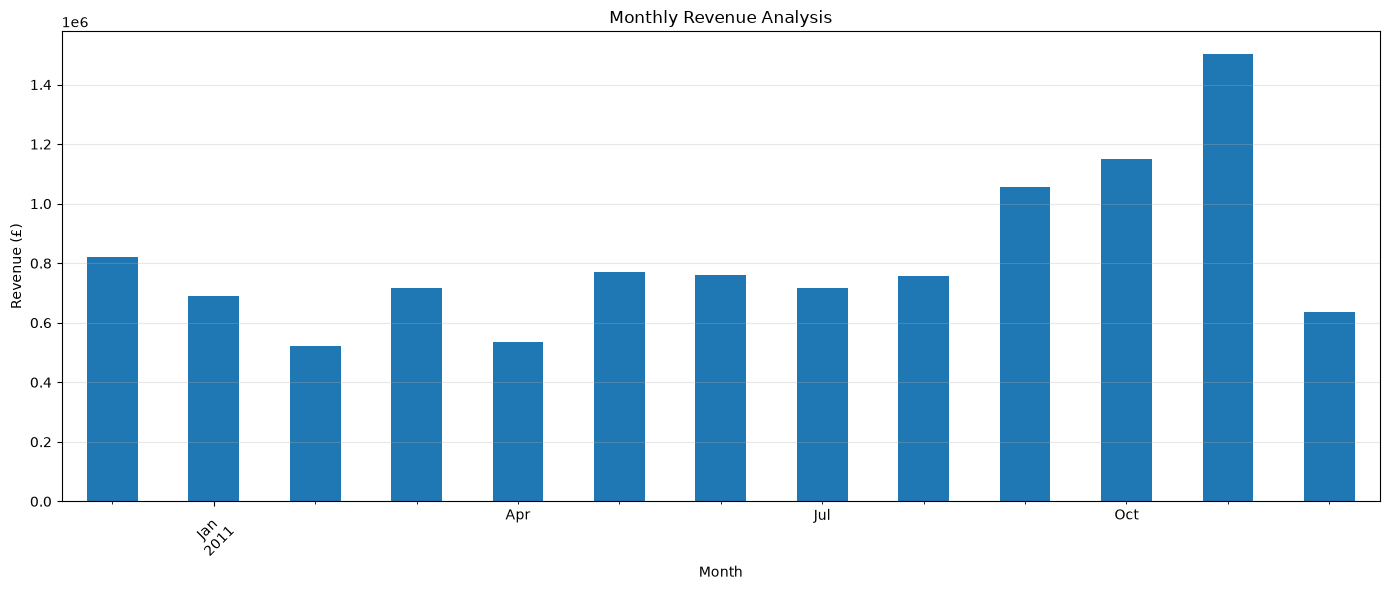

In [29]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
best_month = monthly_sales.idxmax()
highest_revenue = monthly_sales.max()

print("Best Sales Month:", best_month)
print("Highest Revenue:", round(highest_revenue, 2))

Best Sales Month: 2011-11
Highest Revenue: 1503866.78


In [31]:
country_sales = sales_df.groupby("Country")["TotalPrice"].sum()

country_sales = country_sales.sort_values(ascending=False)

country_sales.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: TotalPrice, dtype: float64

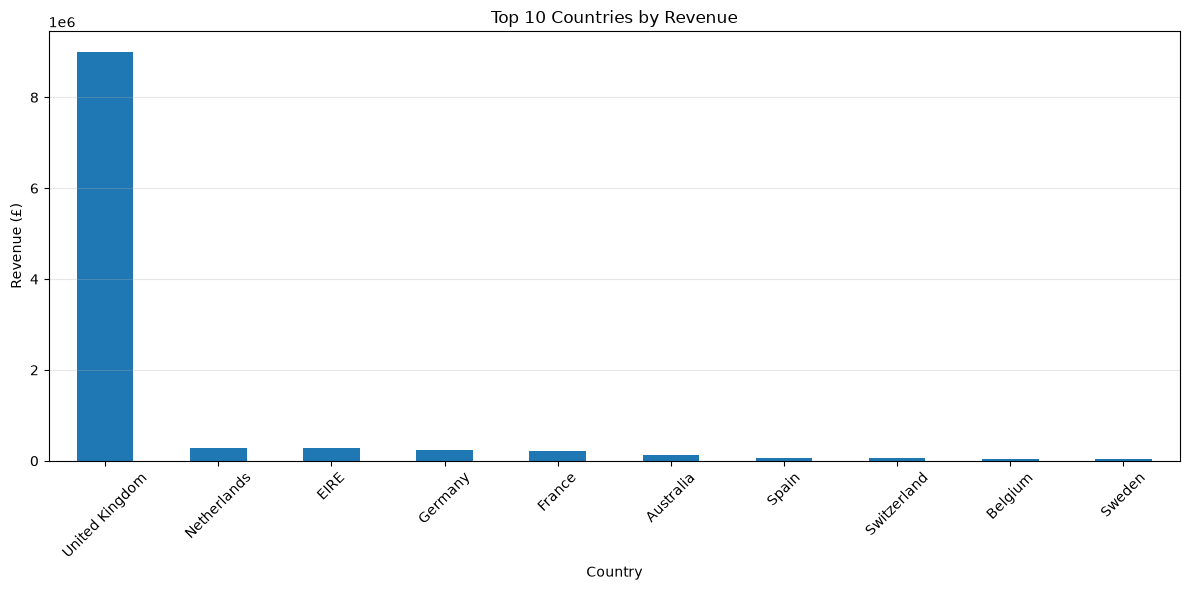

In [32]:
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

top_countries.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
country_orders = sales_df.groupby("Country")["InvoiceNo"].nunique()

country_orders = country_orders.sort_values(ascending=False)

country_orders.head(10)

Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64

In [34]:
best_country = country_sales.idxmax()
highest_revenue = country_sales.max()

print("Top Revenue Country:", best_country)
print("Highest Revenue:", round(highest_revenue, 2))

Top Revenue Country: United Kingdom
Highest Revenue: 9001744.09


In [35]:
product_sales = sales_df.groupby(
    ["StockCode", "Description"]
).agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("TotalPrice", "sum")
).reset_index()

top_products = product_sales.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

top_products

,StockCode,Description,Total_Quantity,Total_Revenue
4150,DOT,DOTCOM POSTAGE,706,206248.77
1262,22423,REGENCY CAKESTAND 3 TIER,13851,174156.54
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24
2669,47566,PARTY BUNTING,18283,99445.23
3761,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
4153,POST,POSTAGE,3150,78101.88
4151,M,Manual,6984,77750.27
1951,23084,RABBIT NIGHT LIGHT,30739,66870.03


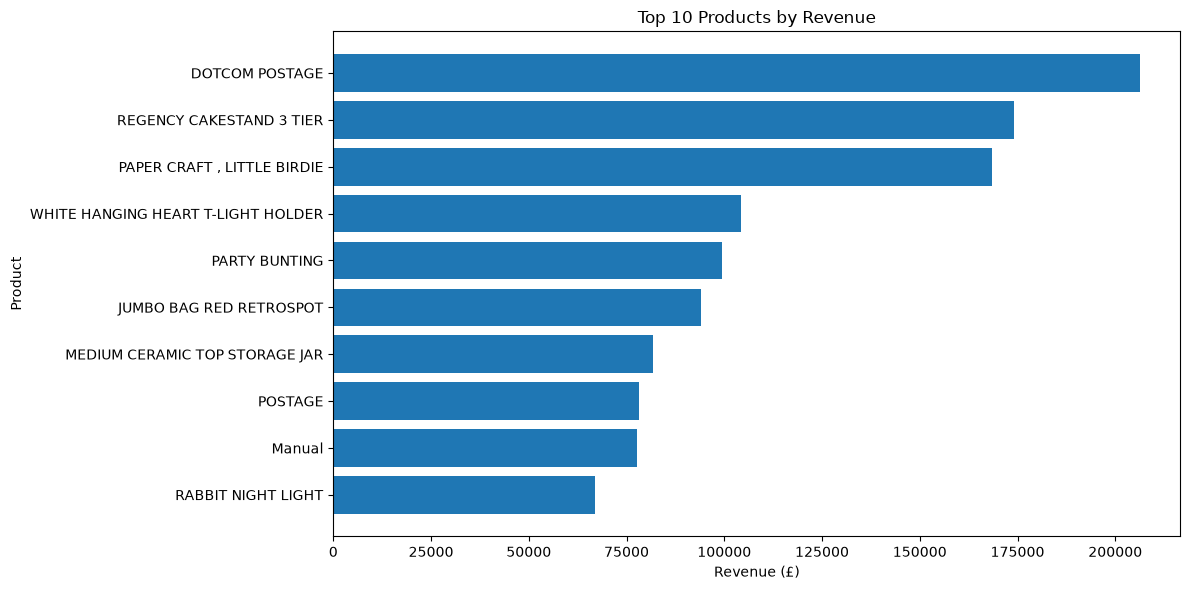

In [36]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products["Description"],
    top_products["Total_Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [37]:
top_quantity = product_sales.sort_values(
    by="Total_Quantity",
    ascending=False
).head(10)

top_quantity

,StockCode,Description,Total_Quantity,Total_Revenue
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
3761,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37580,104284.24
1051,22197,POPCORN HOLDER,36749,34288.67
370,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
1951,23084,RABBIT NIGHT LIGHT,30739,66870.03
1327,22492,MINI PAINT SET VINTAGE,26633,16937.82


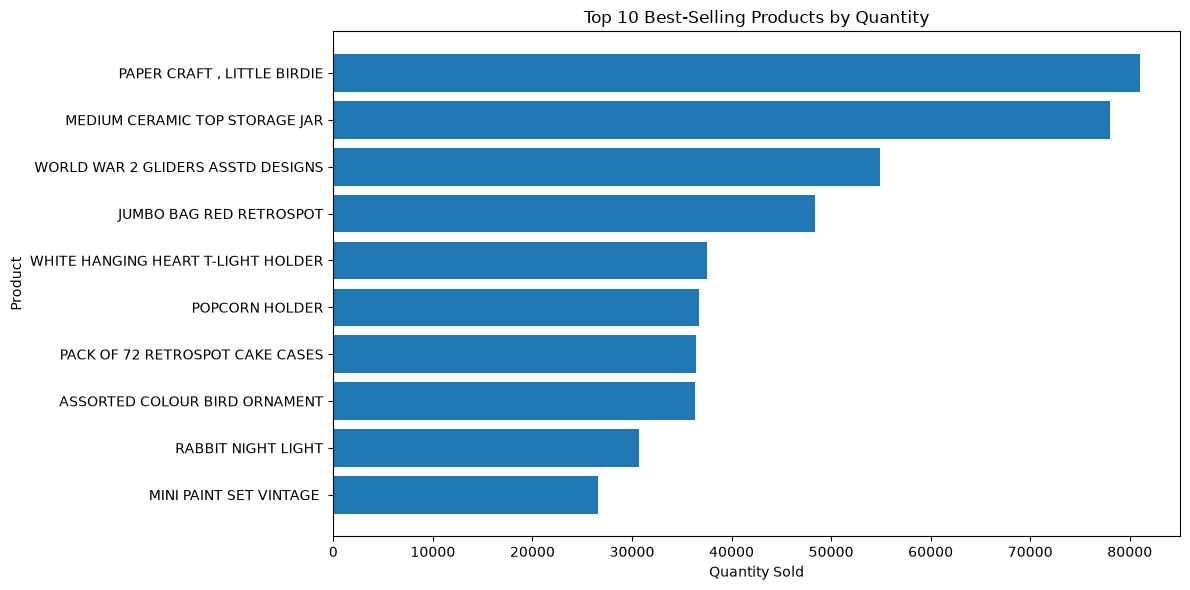

In [38]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_quantity["Description"],
    top_quantity["Total_Quantity"]
)

plt.title("Top 10 Best-Selling Products by Quantity")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [39]:
customer_sales = sales_df.dropna(
    subset=["CustomerID"]
).groupby("CustomerID").agg(
    Total_Orders=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Total_Spending=("TotalPrice", "sum")
).reset_index()

customer_sales.head()

,CustomerID,Total_Orders,Total_Quantity,Total_Spending
0,12346.0,1,74215,77183.60
1,12347.0,7,2458,4310.00
2,12348.0,4,2341,1797.24
3,12349.0,1,631,1757.55
4,12350.0,1,197,334.40


In [40]:
top_customers = customer_sales.sort_values(
    by="Total_Spending",
    ascending=False
).head(10)

top_customers

,CustomerID,Total_Orders,Total_Quantity,Total_Spending
1689,14646.0,73,196915,280206.02
4201,18102.0,60,64124,259657.30
3728,17450.0,46,69973,194390.79
3008,16446.0,2,80997,168472.50
1879,14911.0,201,80240,143711.17
55,12415.0,21,77374,124914.53
1333,14156.0,55,57768,117210.08
3771,17511.0,31,64549,91062.38
2702,16029.0,63,40108,80850.84
0,12346.0,1,74215,77183.60


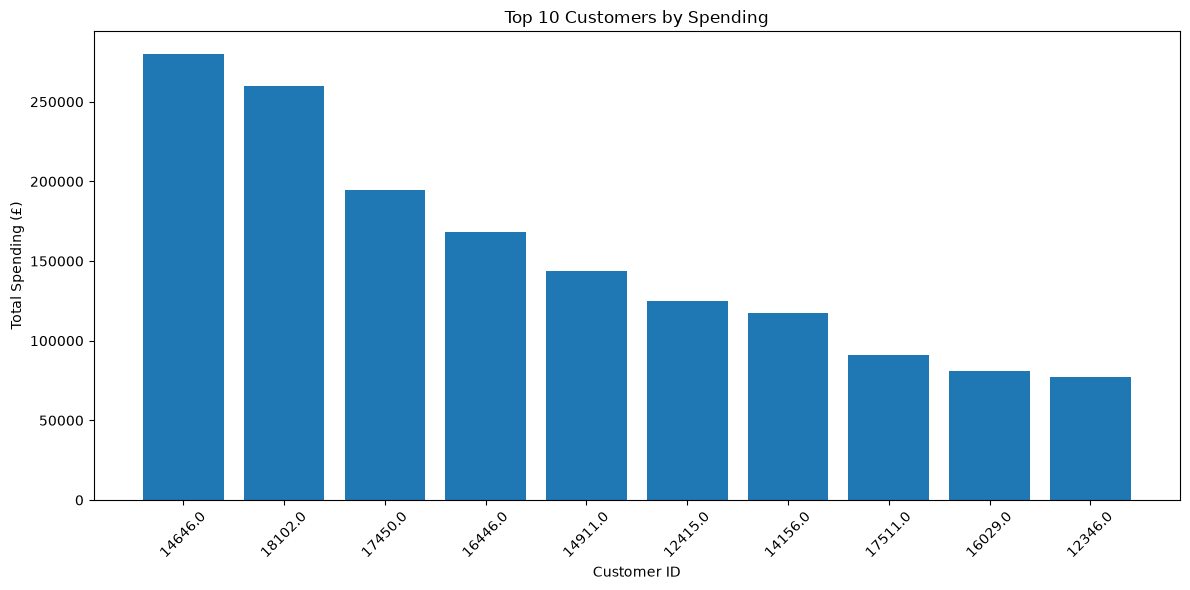

In [41]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["Total_Spending"]
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
total_customers = sales_df["CustomerID"].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 4338


In [43]:
best_customer = top_customers.iloc[0]

print("Top Customer ID:", best_customer["CustomerID"])
print("Total Spending:", round(best_customer["Total_Spending"], 2))
print("Total Orders:", best_customer["Total_Orders"])

Top Customer ID: 14646.0
Total Spending: 280206.02
Total Orders: 73.0


In [44]:
total_revenue = sales_df["TotalPrice"].sum()

total_orders = sales_df["InvoiceNo"].nunique()

total_customers = sales_df["CustomerID"].nunique()

total_products = sales_df["StockCode"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Unique Products:", total_products)

Total Revenue: 10642110.8
Total Orders: 19960
Total Customers: 4338
Unique Products: 3922


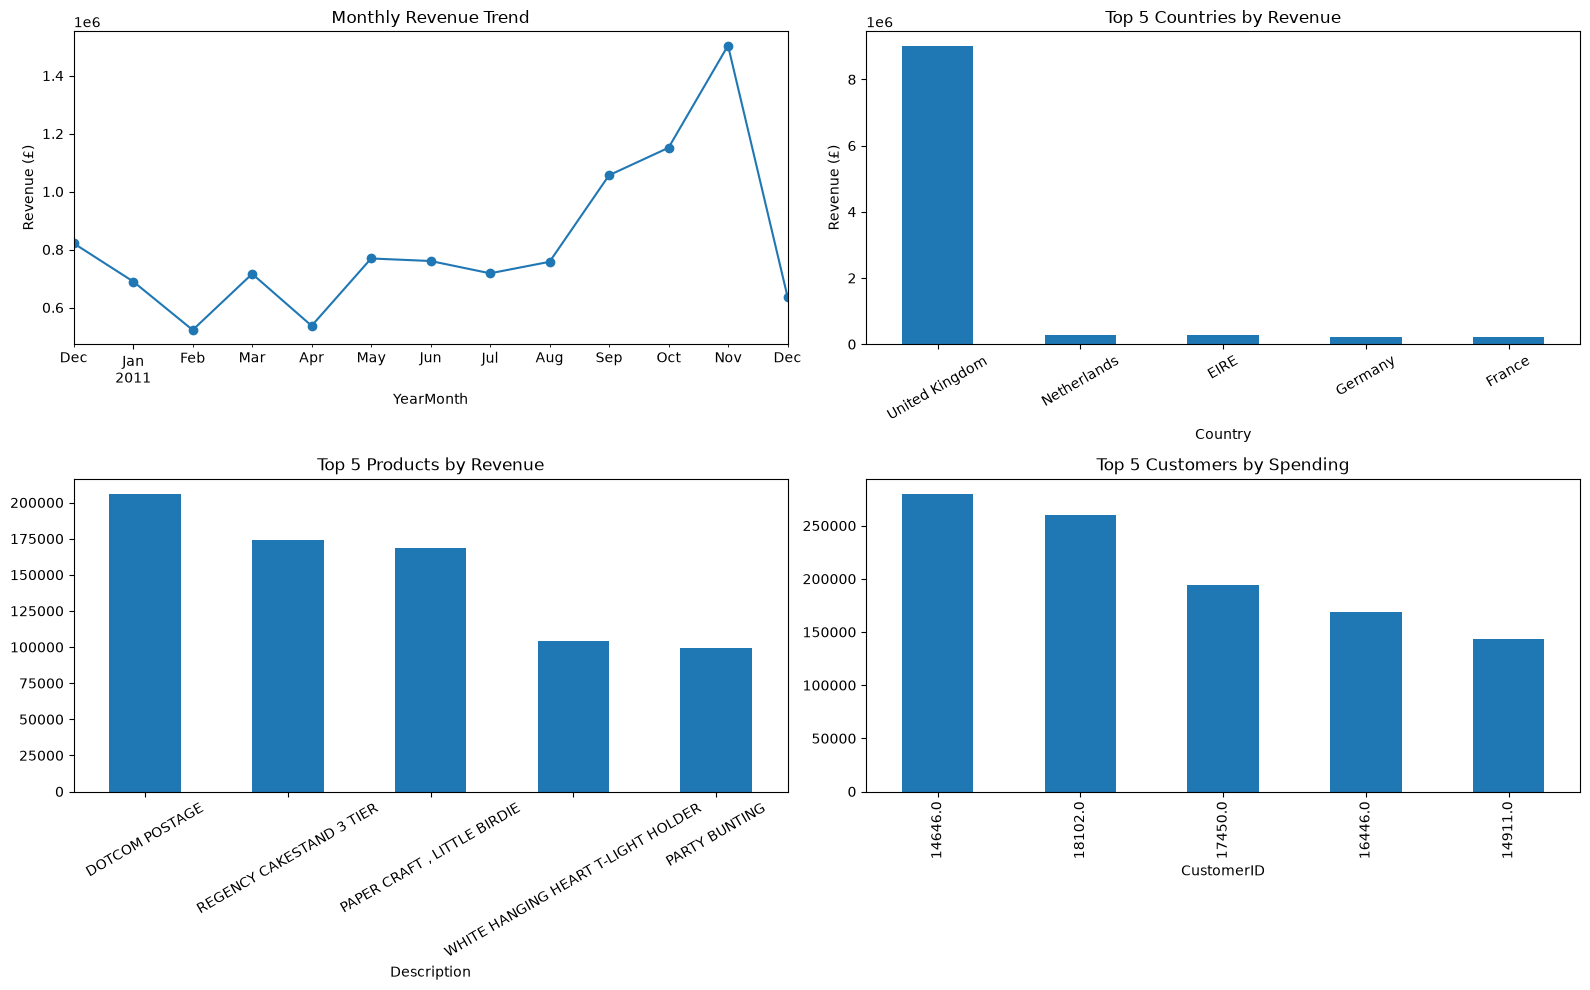

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Monthly Revenue
monthly_sales.plot(kind="line", marker="o", ax=axes[0, 0])
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].set_ylabel("Revenue (£)")

# Top 5 Countries
country_sales.head(5).plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Top 5 Countries by Revenue")
axes[0, 1].set_ylabel("Revenue (£)")
axes[0, 1].tick_params(axis="x", rotation=30)

# Top 5 Products
top_products.head(5).plot(
    x="Description",
    y="Total_Revenue",
    kind="bar",
    ax=axes[1, 0],
    legend=False
)
axes[1, 0].set_title("Top 5 Products by Revenue")
axes[1, 0].tick_params(axis="x", rotation=30)

# Top 5 Customers
top_customers.head(5).plot(
    x="CustomerID",
    y="Total_Spending",
    kind="bar",
    ax=axes[1, 1],
    legend=False
)
axes[1, 1].set_title("Top 5 Customers by Spending")

plt.tight_layout()
plt.show()

In [48]:
fig.savefig(
    "../screenshots/eda_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

In [47]:
import os

# Create screenshots folder if it doesn't exist
os.makedirs("../screenshots", exist_ok=True)

# Save dashboard
fig.savefig(
    "../screenshots/eda_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [49]:
# 1. Overall Revenue
total_revenue = sales_df["TotalPrice"].sum()

# 2. Best Sales Month
best_month = monthly_sales.idxmax()
best_month_revenue = monthly_sales.max()

# 3. Top Country
best_country = country_sales.idxmax()
country_revenue = country_sales.max()

# 4. Top Product
best_product = top_products.iloc[0]["Description"]
product_revenue = top_products.iloc[0]["Total_Revenue"]

# 5. Top Customer
best_customer_id = top_customers.iloc[0]["CustomerID"]
customer_spending = top_customers.iloc[0]["Total_Spending"]

print("========== BUSINESS INSIGHTS ==========")

print(f"Total Revenue: £{total_revenue:,.2f}")

print(f"Best Sales Month: {best_month}")
print(f"Revenue in Best Month: £{best_month_revenue:,.2f}")

print(f"Top Country: {best_country}")
print(f"Country Revenue: £{country_revenue:,.2f}")

print(f"Top Product: {best_product}")
print(f"Product Revenue: £{product_revenue:,.2f}")

print(f"Top Customer ID: {best_customer_id}")
print(f"Customer Spending: £{customer_spending:,.2f}")

========== BUSINESS INSIGHTS ==========
Total Revenue: £10,642,110.80
Best Sales Month: 2011-11
Revenue in Best Month: £1,503,866.78
Top Country: United Kingdom
Country Revenue: £9,001,744.09
Top Product: DOTCOM POSTAGE
Product Revenue: £206,248.77
Top Customer ID: 14646.0
Customer Spending: £280,206.02


In [50]:
average_order_value = (
    sales_df.groupby("InvoiceNo")["TotalPrice"].sum().mean()
)

average_items_per_order = (
    sales_df.groupby("InvoiceNo")["Quantity"].sum().mean()
)

print("Average Order Value:", round(average_order_value, 2))
print("Average Items Per Order:", round(average_items_per_order, 2))

Average Order Value: 533.17
Average Items Per Order: 279.18


In [51]:
insights = f"""
CODEALPHA - EXPLORATORY DATA ANALYSIS

1. Total Revenue: £{total_revenue:,.2f}
2. Best Sales Month: {best_month}
3. Top Country: {best_country}
4. Top Product: {best_product}
5. Top Customer ID: {best_customer_id}
6. Average Order Value: £{average_order_value:,.2f}
7. Average Items Per Order: {average_items_per_order:,.2f}
"""

with open("../business_insights.txt", "w", encoding="utf-8") as file:
    file.write(insights)

print("Business insights saved successfully!")

Business insights saved successfully!
